# Milestone 6: uncertainty quantification (whole furnace, case A)

How much do the outputs of the case A furnace move when the inputs that have a citable or
data-derived uncertainty are varied, and which input matters most?

**Uncertain inputs** (`data/uncertainty.yaml`, sources in `data/SOURCES.md`):

| Group | Inputs | Distribution | Source |
|---|---|---|---|
| kinetics | ln k_j(1023 K), Ea_j of the three steps (6) | multivariate normal, jackknife covariance of the Milestone 2 refit, sampled along principal axes, truncated at ±3σ | Marsigny 2025, Fig. 6 (refit) |
| tortuosity | pellet pore tortuosity | uniform [1, 3] (nominal 2) | Marsigny 2025, §3.5.3 |
| transfer correlation | blend λ of Wakao–Kaguei (0, nominal) and Ranz–Marshall (1) for gas–solid heat and mass transfer | uniform [0, 1] | Wagner 2008; Marsigny 2025 thesis |

**Runs** (`scripts/run_uq.py`, stored in `results/uq/`): 512 Latin-hypercube samples, a grouped
Sobol design (Saltelli, N = 256, 1280 runs) and a grid check of the first 24 samples on 200 and
400 cells. All at 50 cells, which is **not grid-converged** (see the grid check below and the
Milestone 5 grid study). This notebook only reads the stored results; re-running the samples
takes about 1.5 h on 6 cores.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import numpy as np
import pandas as pd
import plot_uq as pu

%matplotlib inline

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
mc = pu.load("mc_50cells.npz")
so = pu.load("sobol_50cells.npz")
nom = pu.nominal(50)  # one deterministic run, ~10 s
ok = mc["converged"]
print(
    f"Monte Carlo: {ok.sum()}/{ok.size} converged ({int(mc['retried'].sum())} needed the "
    f"fallback tolerance), {float(mc['runs_per_minute']):.1f} runs/min on "
    f"{int(mc['workers'])} workers, median {np.median(mc['seconds']):.1f} s per run"
)

Monte Carlo: 512/512 converged (6 needed the fallback tolerance), 24.6 runs/min on 6 workers, median 13.8 s per run


## Output spread (Monte Carlo, 512 samples)

Nominal = the deterministic run with the nominal parameters, same solver settings.

In [2]:
pu.mc_table(mc, nom)

,nominal,mean,std,p05,p50,p95
output,,,,,,
metallization,0.9456,0.946,0.004327,0.94,0.9455,0.9536
h2_consumption_kg_per_t,48.85,48.88,0.2142,48.58,48.85,49.25
top_gas_T_C,363,363.1,0.3189,362.7,363.1,363.6
dri_T_C,268.3,267.4,4.151,260.1,267.8,273.2
peak_solid_T_C,812.5,811.5,4.245,804.4,811.7,817.6
gud,0.3165,0.3166,0.0009328,0.3153,0.3165,0.3182


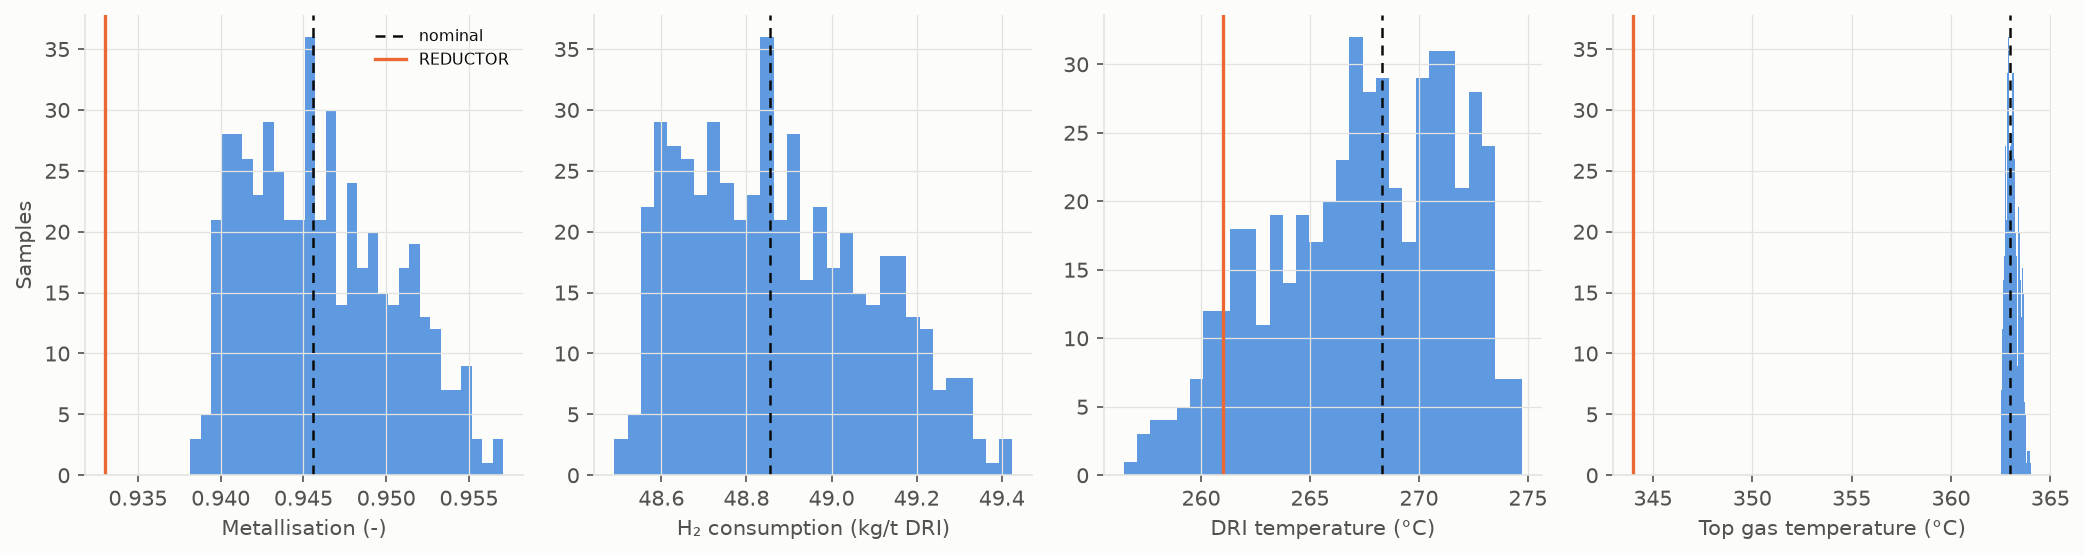

In [3]:
pu.plot_outputs(mc, nom);

The REDUCTOR values (orange) lie outside the sampled range for metallisation and top gas
temperature. Within the uncertainties considered here, the gap to REDUCTOR is therefore not
explained by kinetics, tortuosity or the transfer correlation. The 50-cell grid error is larger
than the spread (next sections), so this figure does not show where the converged model sits.

## Profile bands

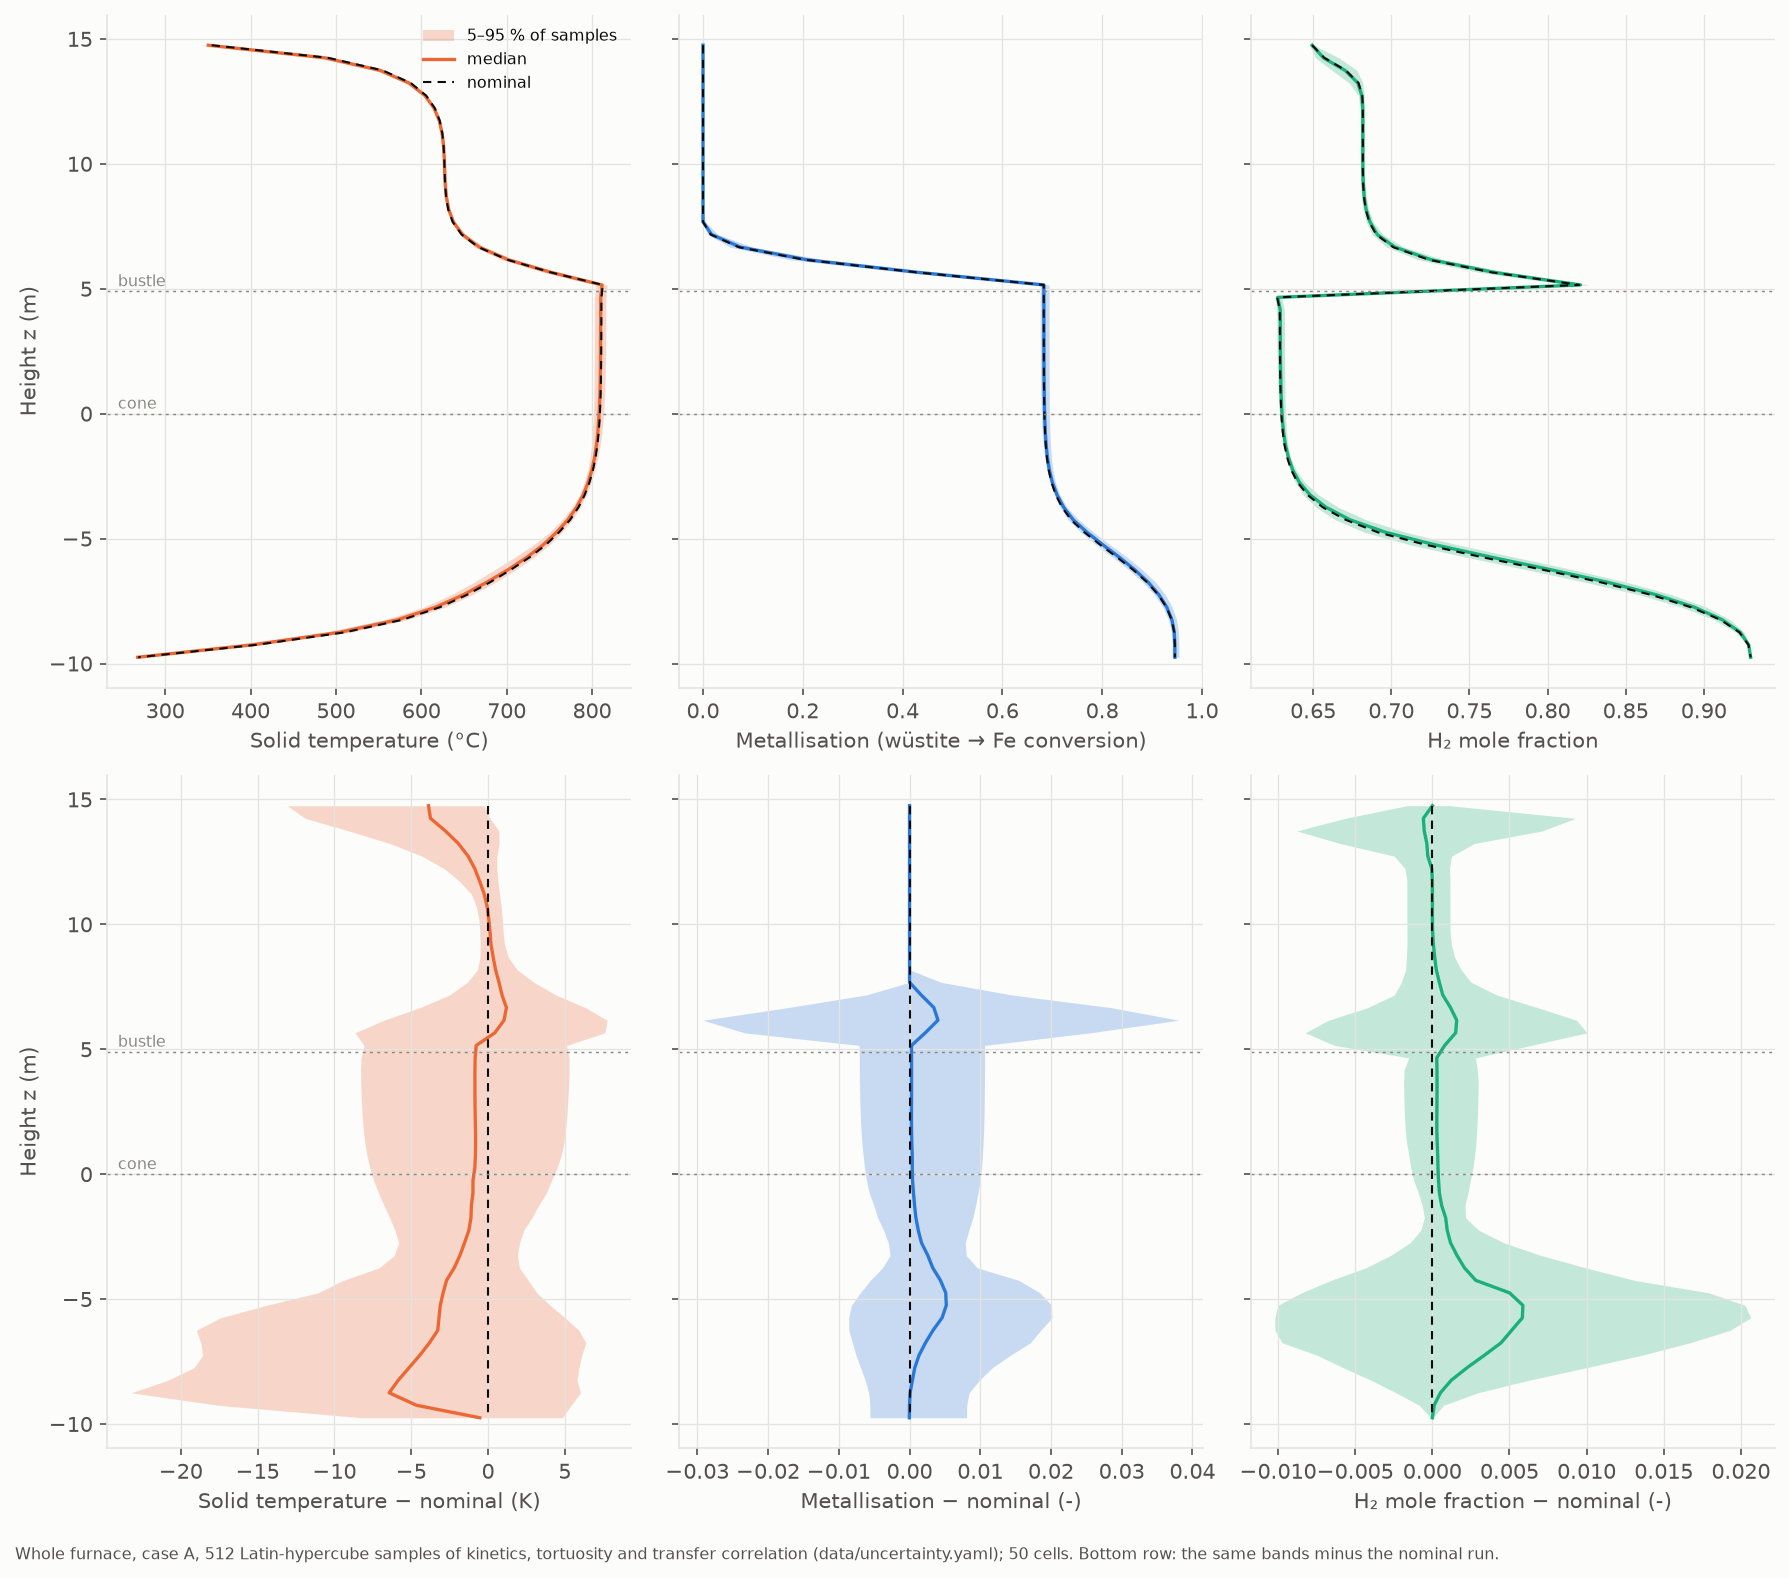

In [4]:
pu.plot_profiles(mc, nom);

The spread is concentrated where something moves: at the reduction front above the bustle
(z ≈ 5–8 m) and at the cooling front in the cone. Elsewhere the bands are narrow.

## Sample-size convergence

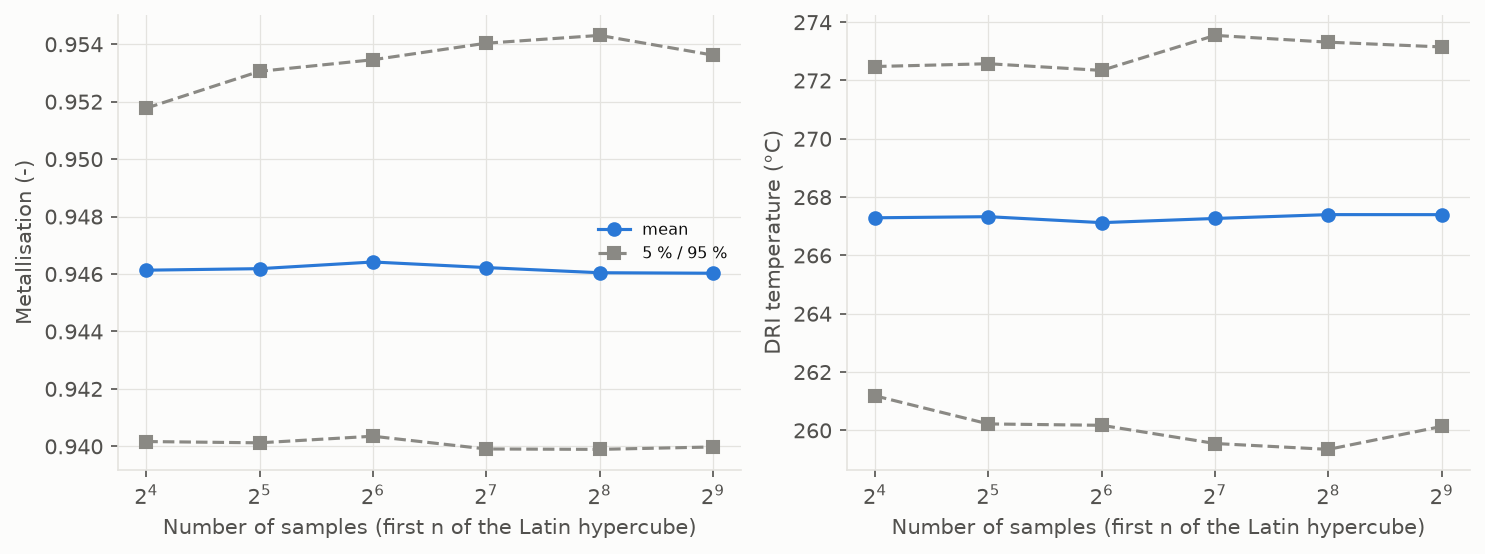

In [5]:
pu.plot_convergence(mc);

## Sobol indices (grouped, N = 256, 95 % bootstrap intervals)

Metallisation, H₂ consumption and gas utilisation are all linear in the oxygen removed, so they
have the same indices.

In [6]:
pu.sobol_table(so)

S1  S1_conf        ST  \
output                  group                                              
metallization           kinetics               0.2156  0.07333    0.2166   
                        tortuosity             0.7842   0.1377    0.7959   
                        transfer correlation 0.002959 0.003105 0.0003033   
h2_consumption_kg_per_t kinetics               0.2156  0.07331    0.2168   
                        tortuosity             0.7841   0.1378     0.796   
                        transfer correlation 0.002951 0.003094  0.000302   
top_gas_T_C             kinetics               0.2862  0.08032     0.285   
                        tortuosity             0.6527   0.1286    0.6681   
                        transfer correlation  0.05557  0.03754    0.0605   
dri_T_C                 kinetics               0.2401  0.07613     0.241   
                        tortuosity             0.7521   0.1362    0.7663   
                        transfer correlation 0.008487   0.0141  0.008161   
peak_solid_T_C          kinetics               0.1809   0.0698    0.1828   
                        tortuosity             0.7957   0.1361    0.7982   
                        transfer correlation   0.0206  0.02468   0.02482   
gud                     kinetics               0.2156  0.07333    0.2166   
                        tortuosity             0.7842   0.1377    0.7959   
                        transfer correlation 0.002959 0.003105 0.0003033   

                                               ST_conf  
output                  group                           
metallization           kinetics               0.04655  
                        tortuosity              0.1196  
                        transfer correlation 0.0001457  
h2_consumption_kg_per_t kinetics               0.04675  
                        tortuosity              0.1197  
                        transfer correlation 0.0001444  
top_gas_T_C             kinetics               0.05699  
                        tortuosity              0.1079  
                        transfer correlation   0.01126  
dri_T_C                 kinetics               0.05096  
                        tortuosity              0.1181  
                        transfer correlation  0.001514  
peak_solid_T_C          kinetics               0.03582  
                        tortuosity              0.1173  
                        transfer correlation  0.004356  
gud                     kinetics               0.04655  
                        tortuosity              0.1196  
                        transfer correlation 0.0001457

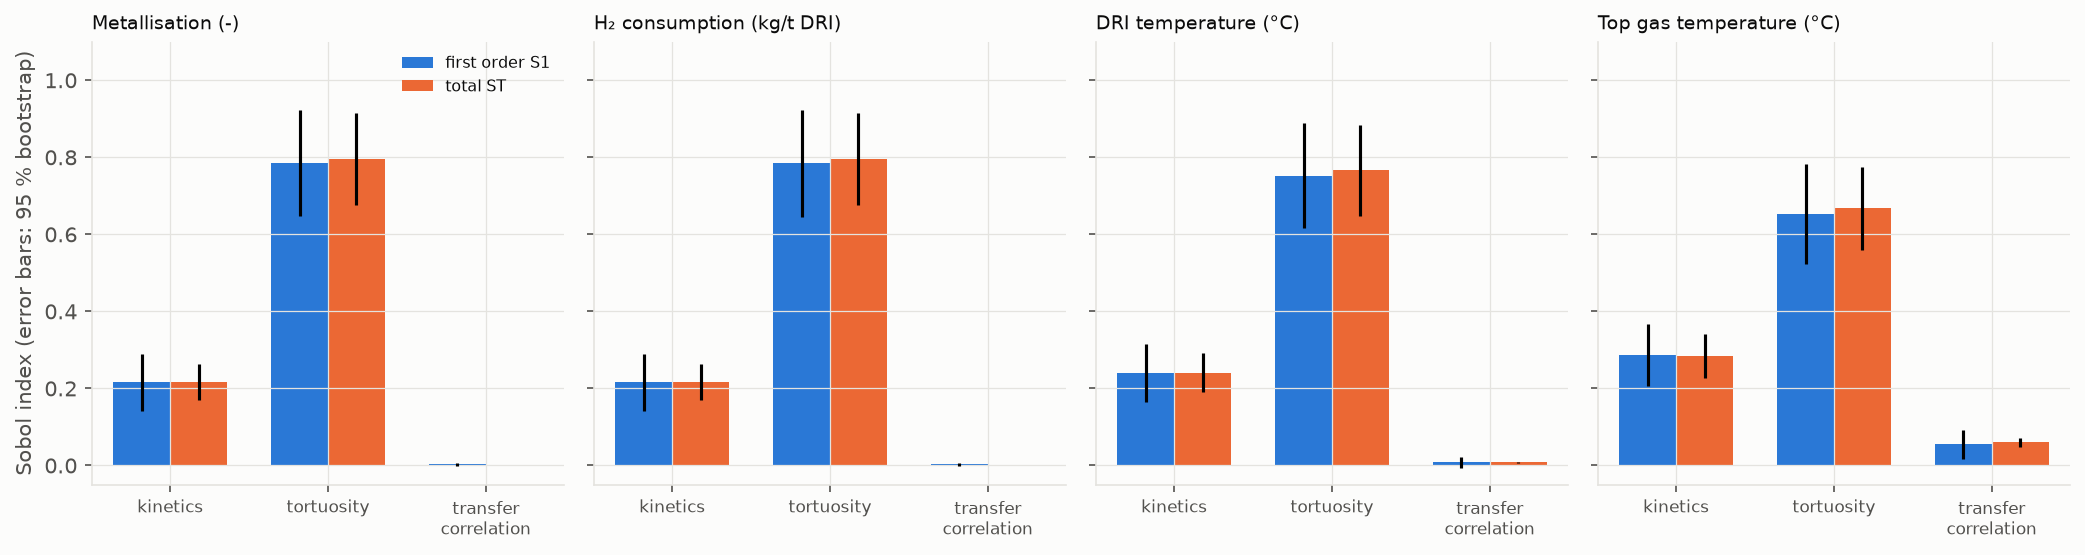

In [7]:
pu.plot_sobol(so);

## Grid check: are the spreads grid-independent?

The same first 24 samples on 50 and on finer grids. The mean offset is the discretisation error
of the 50-cell grid (cf. the Milestone 5 grid study); the standard deviation ratio shows whether
the spread itself depends on the grid.

In [8]:
for cells in (200, 400):
    fine = pu.load(f"grid_{cells}cells.npz")
    if fine is not None:
        print(f"{cells} vs 50 cells")
        display(pu.grid_table(mc, fine))

200 vs 50 cells


,mean offset,std coarse,std fine,std ratio,corr
output,,,,,
metallization,-0.02078,0.003357,0.00241,0.7181,0.9391
h2_consumption_kg_per_t,-1.022,0.1661,0.1179,0.7099,0.9393
top_gas_T_C,-2.072,0.267,0.1806,0.6763,0.9896
dri_T_C,22.12,3.313,2.243,0.677,0.9678
peak_solid_T_C,45.67,3.359,3.324,0.9896,0.959
gud,-0.004479,0.0007236,0.0005196,0.7181,0.9391


400 vs 50 cells


,mean offset,std coarse,std fine,std ratio,corr
output,,,,,
metallization,-0.02847,0.003357,0.002241,0.6677,0.8871
h2_consumption_kg_per_t,-1.397,0.1661,0.1092,0.6573,0.8874
top_gas_T_C,-2.648,0.267,0.1677,0.6281,0.9681
dri_T_C,29.21,3.313,2.053,0.6195,0.9274
peak_solid_T_C,56.83,3.359,3.138,0.9341,0.9057
gud,-0.006138,0.0007236,0.0004831,0.6677,0.8871


- The **mean offsets** are the 50-cell discretisation error and match the Milestone 5 grid
  study (metallisation about −0.03, DRI about +30 K at 400 cells, still not converged).
- The **spreads** shrink to about 0.72× from 50 to 200 cells, and only by a further 0.93× from
  200 to 400 cells: they settle near **0.65×** the 50-cell values (peak solid temperature
  ≈ 0.93×). The 50-cell spreads are therefore a conservative (about 1.5× too wide) estimate.
- The correlation between grids stays at 0.89–0.97, so the samples keep their order and the
  Sobol ranking from the 50-cell runs is not a grid artefact.

## What this does and does not show

- It propagates **three** sources of parameter uncertainty that have a citable range or a
  data-derived spread. Pellet properties of case A, operating conditions, the 1D plug-flow
  assumption, the constant pressure and the missing heat losses are **not** varied; the
  Milestone 5 comparison suggests the model-form error (1D vs 2D) is larger than any spread
  here.
- The tortuosity was held at 2 when the kinetics were fitted, so varying it independently
  overstates its effect; its large Sobol share is an upper bound.
- The kinetic covariance comes from seven temperature curves of one pellet type.
- At 50 cells the mean outputs are off by more than the parameter spread; the spreads
  themselves shrink with grid refinement (grid check). The numbers are therefore indicative of
  the relative importance of the inputs, not final uncertainty intervals for the furnace.

Details: `docs/validation.md`, Milestone 6.